# データサイエンス実践A 第10講：遊び心のあるグラフ・グラフを並べる
### 新潟大学 創生学部（2026年度）
**講義日：2026年11月10日（火）**

1. **画像や記号をマーカー**にしたり、**ドーナツグラフ・ゲージ**にしたりして、記憶に残るグラフを作る（AH）。
1. **複数のグラフを並べる**書き方を学ぶ（AI）。
1. CES-Alpha の演習「第10講」の `pie_描画基礎007` は発展（AJ-1）。
1. セルは**上から順番に**実行すること（`Shift + Enter` で実行して次のセルへ進む）。

## 目次
**[前回の振り返り](#前回の振り返り)**

**[AH. 遊び心のあるグラフ](#AH.-遊び心のあるグラフ)**
- [AH-0 今日の完成形](#AH-0-今日の完成形)
- [AH-1 画像をマーカーにする](#AH-1-画像をマーカーにする)
- [AH-2 記号をマーカーにする](#AH-2-記号をマーカーにする)
- [AH-3 背景に画像を敷く](#AH-3-背景に画像を敷く)
- [AH-4 ドーナツグラフ・ゲージ](#AH-4-ドーナツグラフ・ゲージ)

**[AI. 複数のグラフを並べる](#AI.-複数のグラフを並べる)**
- [AI-1 横に並べる・縦に並べる](#AI-1-横に並べる・縦に並べる)

**[AJ. 発展（できる人だけ）](#AJ.-発展（できる人だけ）)**
- [AJ-1 手書き風のグラフ](#AJ-1-手書き風のグラフ)
- [AJ-2 手書き風フォントを入れると（紹介）](#AJ-2-手書き風フォントを入れると（紹介）)
- [AJ-3 動くグラフ（アニメーション）](#AJ-3-動くグラフ（アニメーション）)
- [AJ-4 別の道具で動かす：plotly（紹介）](#AJ-4-別の道具で動かす：plotly（紹介）)
- [AJ-5 スライダーで動かす（ipywidgets）](#AJ-5-スライダーで動かす（ipywidgets）)

**[まとめ](#まとめ)**

---
# 前回の振り返り

- 前回は、数値を区間ごとに数えて分布を見る**ヒストグラム**（`plt.hist`）と、平均とばらつきを点と線で表す**エラーバー**（`plt.errorbar`）を学んだ
- ここまでで、折れ線・散布図・棒・円・箱ひげ図・複合グラフ（両 y 軸）・ヒストグラム・エラーバーを描けるようになった
- 今日は、グラフを**記憶に残る**ものにする工夫と、**複数のグラフを並べる**書き方を学ぶ
- 今日使う画像 `sweets_montblanc.png` を、notebook と同じいつもの場所（ホームフォルダ）に置いておく

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

from matplotlib.offsetbox import OffsetImage, AnnotationBbox

- 2行目の `from matplotlib.offsetbox import …` は、画像をマーカーにするための道具（AH-1 で使う）

---
# AH. 遊び心のあるグラフ

## AH-0 今日の完成形

月ごとのモンブランの売上を、**モンブランの画像**をマーカーにして描いたもの。

1. **全部コピーして**自分の notebook のセルに貼り付け、実行する
1. まずは**数や大きさを変えて**、グラフのどこが変わるかを確かめる
1. そのあと部品（[1]〜[3]）の働きを1つずつ学ぶ（AH-1〜AH-3）

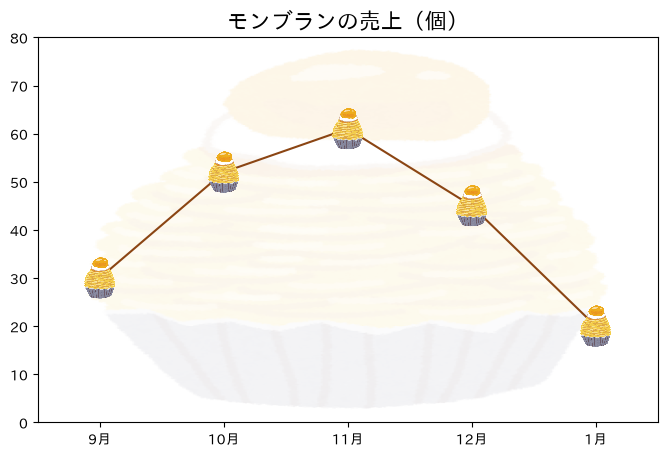

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib
from matplotlib.offsetbox import OffsetImage, AnnotationBbox

img = plt.imread('sweets_montblanc.png')  # [1] 画像を読む
y = [30, 52, 61, 45, 20]

plt.figure(figsize=(8, 5))
plt.plot([0, 1, 2, 3, 4], y, color='saddlebrown', zorder=1)
for i in range(len(y)):  # [2] 画像のマーカー
    box = AnnotationBbox(OffsetImage(img, zoom=0.08), (i, y[i]), frameon=False)
    plt.gca().add_artist(box)
plt.imshow(img, extent=[-0.5, 4.5, 0, 80], alpha=0.1, aspect='auto')  # [3] 背景
plt.xticks([0, 1, 2, 3, 4], ['9月', '10月', '11月', '12月', '1月'])
plt.xlim(-0.5, 4.5)
plt.ylim(0, 80)
plt.title('モンブランの売上（個）', fontsize=16)
plt.show()

### 変えてみよう（1か所変えたら、もう一度実行する）

- `zoom=0.08` → `zoom=0.15`（画像の大きさ）
- `alpha=0.1` → `alpha=0.4`（背景の濃さ）
- `y` の数を変える（例：`[30, 52, 61, 45, 20]` → `[10, 20, 70, 60, 30]`）

| 番号 | 部品 | 書き方 | 学ぶところ |
|---|---|---|---|
| [1] | 画像を読む | `img = plt.imread('画像ファイル名')` | AH-1 |
| [2] | 画像のマーカー | `for` で1つずつ `AnnotationBbox(OffsetImage(img, zoom=…), (x, y))` | AH-1 |
| [3] | 背景の画像 | `plt.imshow(img, extent=[…], alpha=0.1, aspect='auto')` | AH-3 |

In [3]:
# 上のコードを貼り付けて、値を変えてみよう

## AH-1 画像をマーカーにする

- 下のセルは**ひな形**。写して使えばよく、1行ずつ覚えなくてよい
- 変えるのは `画像ファイル名`・`x`・`y`・`zoom`（画像の大きさ）だけ
- 画像は、背景が透明な png（「いらすとや」の画像など）を使うときれいに見える

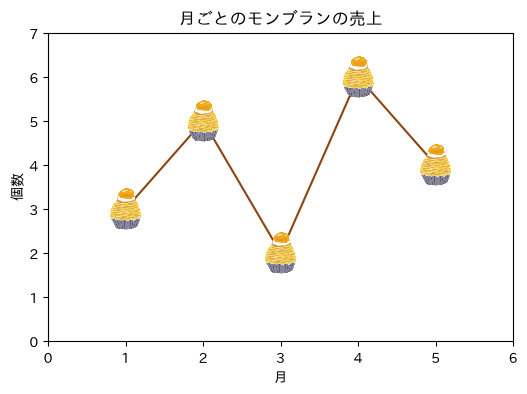

In [4]:
img = plt.imread('sweets_montblanc.png')
x = [1, 2, 3, 4, 5]
y = [3, 5, 2, 6, 4]

plt.figure(figsize=(6, 4))
plt.plot(x, y, color='saddlebrown', zorder=1)
for i in range(len(x)):
    box = AnnotationBbox(OffsetImage(img, zoom=0.08), (x[i], y[i]), frameon=False)
    plt.gca().add_artist(box)
plt.xlim(0, 6)
plt.ylim(0, 7)
plt.title('月ごとのモンブランの売上')
plt.xlabel('月')
plt.ylabel('個数')
plt.show()

- `for i in range(len(x)):` で、点の数だけ画像を置いている。for 文は第12講で学ぶ。ここでは写して使えばよい
- `(x[i], y[i])` は i 番目の点の位置
- 画像は `plt.xlim`・`plt.ylim` の範囲を自動で広げない。範囲は自分で指定する

## AH-2 記号をマーカーにする

- 第３講のハートのように、`$` で囲んだ記号をマーカーにできる
- `'$\\star$'`（星）、`'$\\clubsuit$'`（クラブ）、`'$\\bigodot$'`（二重丸）など。文字そのもの `'$A$'` も使える

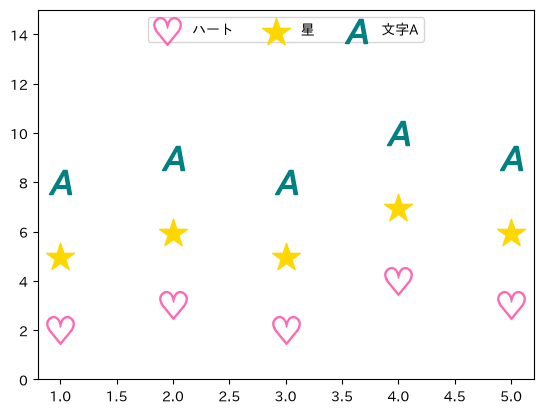

In [5]:
x = [1, 2, 3, 4, 5]
plt.scatter(x, [2, 3, 2, 4, 3], marker='$\\heartsuit$', s=400, color='hotpink', label='ハート')
plt.scatter(x, [5, 6, 5, 7, 6], marker='$\\star$', s=400, color='gold', label='星')
plt.scatter(x, [8, 9, 8, 10, 9], marker='$A$', s=300, color='teal', label='文字A')
plt.ylim(0, 15)
plt.legend(loc='upper center', ncol=3)
plt.show()

- `\\` は `\` を書くための書き方（Python の文字列の中では `\` を2つ重ねる）
- `s=` はマーカーの大きさ（散布図では `s`、折れ線では `markersize`）

## AH-3 背景に画像を敷く

- `plt.imshow(画像, extent=[x最小, x最大, y最小, y最大])` で、グラフの範囲いっぱいに画像を敷ける
- `alpha=` で薄くする。`aspect='auto'` を付けないと、画像の縦横の比に合わせてグラフがつぶれる

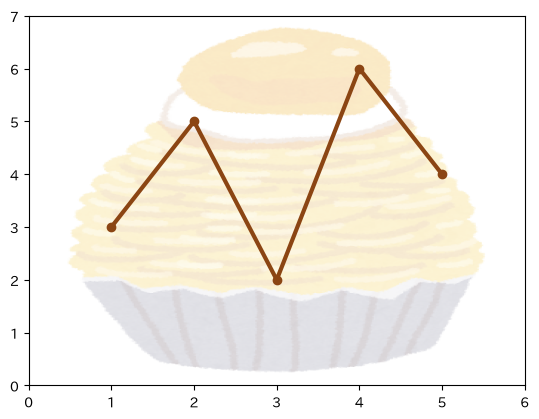

In [6]:
x = [1, 2, 3, 4, 5]
y = [3, 5, 2, 6, 4]
plt.imshow(img, extent=[0, 6, 0, 7], alpha=0.25, aspect='auto')
plt.plot(x, y, marker='o', color='saddlebrown', linewidth=3)
plt.xlim(0, 6)
plt.ylim(0, 7)
plt.show()

## AH-4 ドーナツグラフ・ゲージ

- 第６講の円グラフ `plt.pie` に**1つ足すだけ**で、真ん中に穴のあいた**ドーナツグラフ**になる
- 穴に大きく数字を書くと、「何%か」がひと目で伝わる


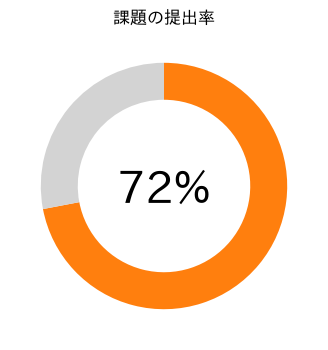

In [7]:
plt.figure(figsize=(4, 4))
plt.pie([72, 28], colors=['tab:orange', 'lightgray'], startangle=90, counterclock=False,  # [1] 12時から時計回り
        wedgeprops={'width': 0.3})  # [2] 輪の太さ（円の半径を 1 としたとき）
plt.text(0, 0, '72%', ha='center', va='center', fontsize=32)  # [3] 真ん中の穴に数字
plt.title('課題の提出率')
plt.show()


| 番号 | 何をしているか |
|---|---|
| [1] | `startangle=90` で12時の位置から、`counterclock=False` で時計回りに塗る |
| [2] | `wedgeprops={'width': 0.3}` で、外側から 0.3 の太さの輪だけを残す（`{ }` は辞書、第７講） |
| [3] | 円グラフの真ん中は (0, 0)。`ha`・`va` は文字の横・縦をそろえる位置（`'center'` で真ん中） |

### 半分にするとゲージになる
- 車のスピードメーターのような**半円のゲージ**も作れる
- しかけは、**合計（72 + 28 = 100）と同じ大きさの白い部分を足して下半分にし、`plt.ylim` で切り落とす**こと


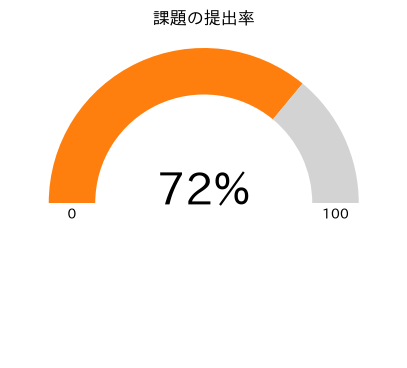

In [8]:
plt.figure(figsize=(5, 3))
plt.pie([72, 28, 100], colors=['tab:orange', 'lightgray', 'white'], startangle=180, counterclock=False,  # [1] 9時から時計回り
        wedgeprops={'width': 0.3})
plt.ylim(-0.2, 1.1)  # [2] 下半分（白い部分）を切り落とす
plt.text(0, 0.1, '72%', ha='center', va='center', fontsize=32)
plt.text(-0.85, -0.1, '0', ha='center')  # [3] 両端に目盛り
plt.text(0.85, -0.1, '100', ha='center')
plt.title('課題の提出率')
plt.show()


| 番号 | 何をしているか |
|---|---|
| [1] | `startangle=180` で9時（左端）から、時計回りに上を通って右へ塗る。3つ目の `100` が見えない下半分 |
| [2] | 円は縦が -1〜1。`plt.ylim(-0.2, 1.1)` で、上半分と目盛りの文字のところだけを見せる |
| [3] | 輪の真ん中は半径 0.85（1 − 0.3 ÷ 2）なので、`x` を ±0.85 にすると両端の下に文字が来る |

### 変えてみよう
- `72` と `28` を `40` と `60` に（文字の `'72%'` も直す）
- `'width': 0.3` → `0.1`（細い輪）
- `'tab:orange'` → `'tab:green'`


### 使ってみよう
- 好きな画像（png）を同じフォルダに置き、AH-1 のひな形の `'sweets_montblanc.png'` を書き換えてみよう
- データは自分で考えた数でよい（例：1週間に飲んだコーヒーの杯数）

In [9]:
# ここで試してみよう

---
# AI. 複数のグラフを並べる

## AI-1 横に並べる・縦に並べる

- 比べたいグラフは、横に並べると見比べやすい
- `plt.subplot(縦の数, 横の数, 何番目)` のあとに書いたものが、その位置のグラフに描かれる
- 番号は左上から 1, 2, 3, … と数える。最後に `plt.tight_layout()` で重なりを自動で調整する

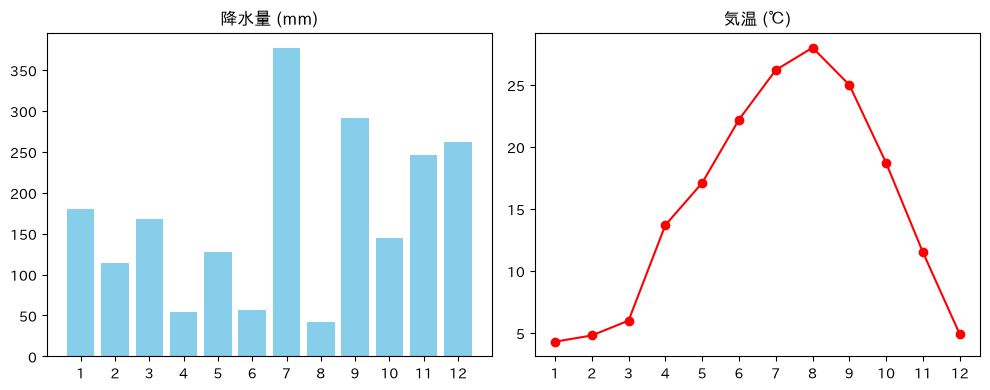

In [10]:
df_rain = pd.read_excel('dsa2026data.xlsx', sheet_name='降水量')

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.bar(df_rain['月'], df_rain['降水量'], color='skyblue')
plt.title('降水量 (mm)')
plt.xticks(range(1, 13))

plt.subplot(1, 2, 2)
plt.plot(df_rain['月'], df_rain['気温'], color='r', marker='o')
plt.title('気温 (℃)')
plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

- 第８講の複合グラフ（`plt.twinx()`）は1つのグラフに重ねる書き方、`plt.subplot` は別々のグラフを並べる書き方
- 縦に並べるときは `plt.subplot(2, 1, 1)`、`plt.subplot(2, 1, 2)`
- 第11講では、誤解を招くグラフと正しいグラフをこの書き方で並べて比べる

---
# AJ. 発展（できる人だけ）

## AJ-1 手書き風のグラフ

- `with plt.xkcd():` の下に字下げして書くと、手書き風になる
- **2行目のフォントの指定は必ず写す**。手書き風にすると文字が英語用のフォントに切り替わり、日本語が □ になるため
  - `'Comic Sans MS'`（英数字を手書き風に）→ 無い文字は `'IPAexGothic'`（japanize_matplotlib に入っている日本語フォント）で表示される
- 字下げした部分だけが手書き風になる。次のセルからは元に戻る

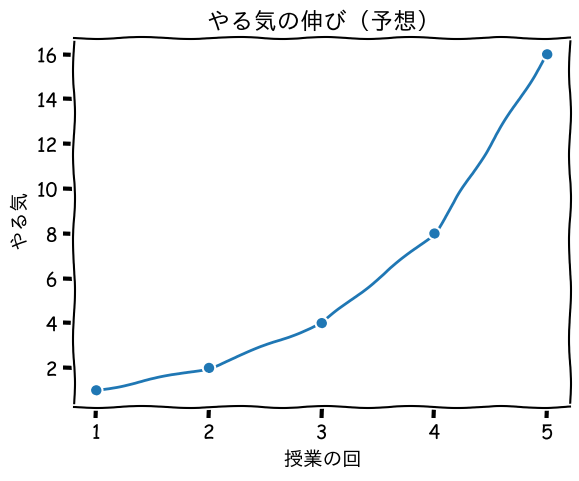

In [11]:
with plt.xkcd():
    plt.rcParams['font.family'] = ['Comic Sans MS', 'IPAexGothic']
    plt.plot([1, 2, 3, 4, 5], [1, 2, 4, 8, 16], marker='o')
    plt.title('やる気の伸び（予想）')
    plt.xlabel('授業の回')
    plt.ylabel('やる気')
    plt.show()

- Mac で `Comic Sans MS` が無いときは、英数字も `IPAexGothic` で表示される（エラーにはならない）
- `with ○○:` は、**字下げした部分の間だけ**設定を変え、終わったら元に戻す書き方。第５講 K-6 の `with plt.style.context('ggplot'):`（スタイルシート）も同じ仕組み
- 色の組み合わせ（カラーマップ）も、`with mpl.rc_context(...):` でそのグラフの間だけ変えられる（第６講 P-2 では `colors=` で指定した）
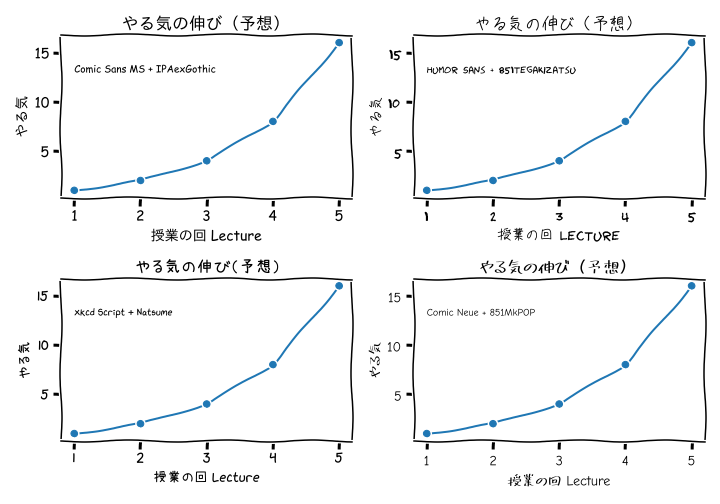

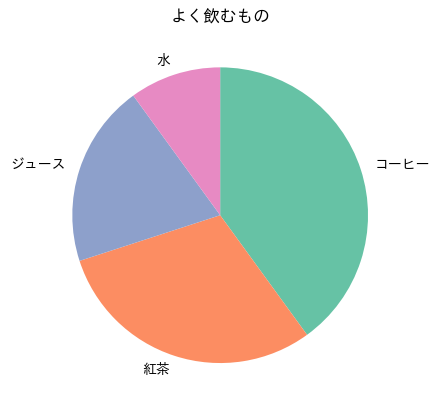

In [12]:
import matplotlib as mpl
from cycler import cycler

with mpl.rc_context({'axes.prop_cycle': cycler(color=plt.get_cmap('Set2').colors)}):
    plt.pie([40, 30, 20, 10], labels=['コーヒー', '紅茶', 'ジュース', '水'], counterclock=False, startangle=90)
    plt.title('よく飲むもの')
    plt.show()

- `cycler(color=色のリスト)` で、グラフが順に使う色を決める。`plt.get_cmap('Set2').colors` は Set2 の色のリスト
- `colors=` を書くと、そちらが優先される（カラーマップの色にならない）。カラーマップを使うときは `colors=` を消す
- 使うには `import matplotlib as mpl` と `from cycler import cycler` が必要

▶ **演習**（発展）：`pie_描画基礎007`（`with` でカラーマップを切り替える）

## AJ-2 手書き風フォントを入れると（紹介）

- パソコンに手書き風のフォントを入れると、文字ももっと手書きらしくできる
- 下の図は、無料で配布されているフォントを入れたパソコンで描いたもの（左上が AJ-1 の組み合わせ）

![xkcd_fonts.png](attachment:xkcd_fonts.png)

| 種類 | フォント | `font.family` に書く名前 |
|---|---|---|
| 英数字 | Humor Sans（xkcd の漫画の文字） | `'Humor Sans'` |
| 英数字 | xkcd Script | `'xkcd Script'` |
| 英数字 | Comic Neue | `'Comic Neue'` |
| 日本語 | 851手書き雑フォント | `'851tegakizatsu'` |
| 日本語 | なつめもじ | `'Natsume'` |
| 日本語 | 851マカポップ | `'851MkPOP'` |

### フォントの入れ方（例：851マカポップ）

1. [851MkPOP_101.ttf](https://pm85122.onamae.jp/851MkPOP_101.ttf) をダウンロードする（約 4.5MB）。ほかのフォントは、フォント名で検索すると配布ページが見つかる
1. ダウンロードしたファイルを開いて「インストール」（Windows は右クリック →「インストール」、Mac はダブルクリック →「Font Book」で「インストール」）
1. matplotlib が覚えているフォントの一覧（キャッシュ）を消す。下のセルで出てくるフォルダ（Windows は `C:\Users\自分の名前\.matplotlib`、Mac はホームフォルダの `.matplotlib`）を開き、`fontlist-` で始まる `.json` ファイル（例：`fontlist-v3.11.0.json`）を**全部**消す
   - `.` で始まるフォルダは隠しフォルダ。Windows はエクスプローラーの「表示」→「隠しファイル」にチェック、Mac は Finder で `Command` + `Shift` + `.`（ピリオド）
1. Kernel → Restart して、もう一度 `import` から実行する

```python
import matplotlib
print(matplotlib.get_cachedir())
```

- 書く名前はファイル名と違うことがある。入れたフォントの名前は、下のセルで一覧を出して探す


In [13]:
from matplotlib import font_manager
names = sorted({f.name for f in font_manager.fontManager.ttflist})
print(names)

['$\x82i\x82r\x83S\x83V\x83b\x83N', '$\x82i\x82r\x96¾\x92©', '%Century Oldstyle', '%CenturyOldst', '&CenturyOldst', '&Gothic720', '851MkPOP', '851tegakizatsu', '???????W3', 'Adobe Devanagari', 'Agency FB', 'Algerian', 'Arial', 'Arial Black', 'Arial Narrow', 'Arial Rounded MT Bold', 'Arphic Gansinkaisho4 Heavy JIS', 'Arphic Gothic4 Medium JIS', 'Arphic Gothic4 SuperBold JIS', 'Arphic Kaisho4 Medium JIS', 'Arphic Kaisho4JIS', 'Arphic Kanteiryu4 Heavy JIS', 'Arphic Kyokashotai4 Medium JIS', 'Arphic Kyokashotai4JIS', 'Arphic Marker-Tai4 Extra JIS', 'Arphic Match-Tai4 Bold JIS', 'Arphic Mincho4 Light JIS', 'Arphic Mincho4 Ultra JIS', 'Arphic PGansinkaisho4 Heavy JIS', 'Arphic PGothic4 Medium JIS', 'Arphic PGothic4 SuperBold JIS', 'Arphic PKaisho4 Medium JIS', 'Arphic PKaisho4JIS', 'Arphic PKanteiryu4 Heavy JIS', 'Arphic PKyokashotai4 Medium JIS', 'Arphic PKyokashotai4JIS', 'Arphic PMarker-Tai4 Extra JIS', 'Arphic PMatch-Tai4 Bold JIS', 'Arphic PMincho4 Light JIS', 'Arphic PMincho4 Ultra JIS

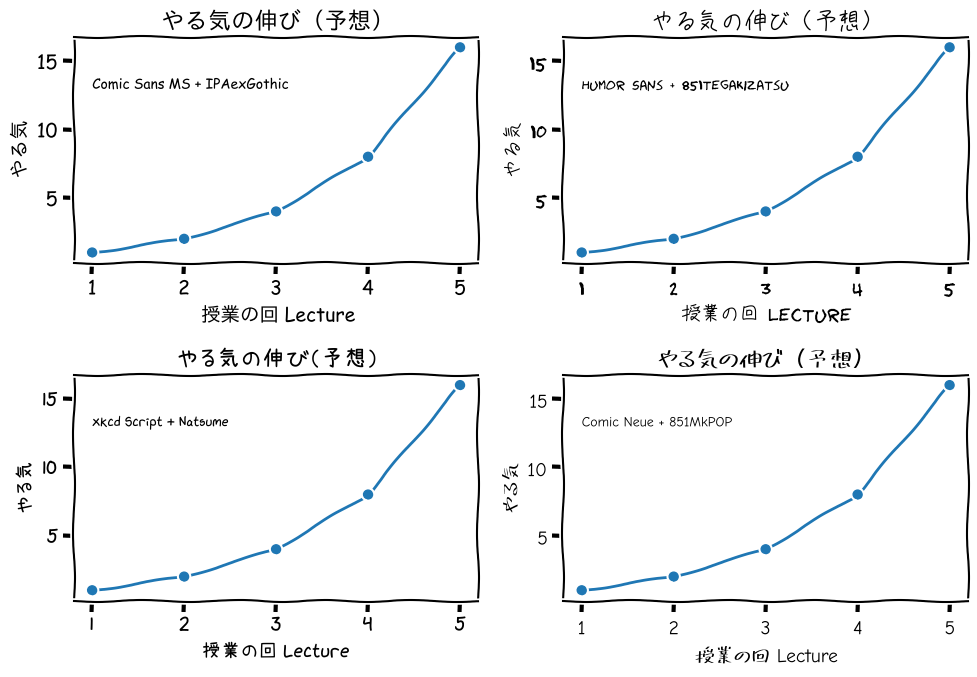

In [14]:
fonts = [
    ['Comic Sans MS', 'IPAexGothic'],
    ['Humor Sans', '851tegakizatsu', 'IPAexGothic'],
    ['xkcd Script', 'Natsume', 'IPAexGothic'],
    ['Comic Neue', '851MkPOP', 'IPAexGothic'],
]

with plt.xkcd():
    plt.figure(figsize=(10, 7))
    for i in range(len(fonts)):
        plt.rcParams['font.family'] = fonts[i]
        plt.subplot(2, 2, i + 1)
        plt.plot([1, 2, 3, 4, 5], [1, 2, 4, 8, 16], marker='o')
        plt.title('やる気の伸び（予想）')
        plt.xlabel('授業の回 Lecture')
        plt.ylabel('やる気')
        plt.text(1, 13, fonts[i][0] + ' + ' + fonts[i][1], fontsize=10)
    plt.tight_layout()
    plt.show()

- 最後の `'IPAexGothic'` は、フォントが入っていないときの予備。入っていない人が実行しても日本語は □ にならない
- フォントを入れたのに変わらないとき、`findfont: Font family '851MkPOP' not found.` と出るときは、キャッシュを消していないか、消した後に Kernel → Restart していない（上の「フォントの入れ方」の 3・4）


## AJ-3 動くグラフ（アニメーション）

- 線が左から少しずつ伸びていく、**動くグラフ**を作る
- 「1枚目の絵、2枚目の絵、…」と**少しずつ違う絵を何枚も描いて、パラパラ漫画のように続けて見せる**仕組み
- 関数を作る `def`（第13講）を**先取り**して使う。今は、下のコードを写して、数や色を変えて遊べればよい

In [15]:
import matplotlib.animation as animation
from IPython.display import HTML

x = np.linspace(0, 2 * np.pi, 40)  # 0 から 2π までを 40 個に区切った数
y1 = np.sin(x)
y2 = np.cos(x)

fig = plt.figure(figsize=(6, 4), dpi=72)  # [1] グラフを用意する（dpi は絵の細かさ）
plt.plot(x[0], y1[0], marker='o', label='sin')  # [2] 最初の1点だけ描いておく
plt.plot(x[0], y2[0], marker='o', label='cos')
lines = plt.gca().get_lines()  # [3] 描いた2本の線を取り出す（lines[0] が sin、lines[1] が cos）
plt.xlim(x[0], x[-1])
plt.ylim(-1.1, 1.1)
plt.title('動くグラフ')
plt.legend(loc='upper right')

def update(i):  # [4] i 枚目の絵：最初から i 番目までの点で線を描き直す
    lines[0].set_data(x[:i + 1], y1[:i + 1])
    lines[1].set_data(x[:i + 1], y2[:i + 1])

ani = animation.FuncAnimation(fig, update, frames=len(x), interval=50)  # [5] 40 枚を 50 ミリ秒ごとに
plt.close()  # 止まった絵が別に出ないようにする
HTML(ani.to_jshtml())  # [6] notebook の中で再生する

- 下の ▶ ボタンで再生する。速さの調整や、1枚ずつ送ることもできる

| 番号 | 何をしているか |
|---|---|
| [1] | `fig = plt.figure()` で、絵を描き直す先のグラフに名前（`fig`）を付けておく。`dpi=72` は絵の細かさで、小さくすると notebook のファイルが軽くなる（何十枚も絵を作るため） |
| [2] | 最初は1点だけ描く。ここで線の色や `marker=` を決める |
| [3] | `plt.gca().get_lines()` で、描いた線を**リストとして**取り出す。描いた順に `[0]`、`[1]` |
| [4] | `update(i)` は「i 枚目の絵」を作る関数。`x[:i + 1]` は「先頭から i 番目まで」（第７講の `[:-1]` と同じ、リストの一部を取り出す書き方）。`set_data` で線の点を入れ替える |
| [5] | `FuncAnimation` が、`i` を 0, 1, 2, … と変えながら `update` を `frames=` 回呼ぶ。`interval=` は1枚の表示時間（ミリ秒） |
| [6] | Jupyter では `plt.show()` だけだと**止まった絵**になる。`HTML(ani.to_jshtml())` で再生ボタン付きにする |

### 変えてみよう
- `interval=50` → `200`（ゆっくり）
- `marker='o'` → `marker='$\\star$'`（AH-2 の記号のマーカー）
- `np.linspace(0, 2 * np.pi, 40)` の `40` → `100`（なめらかになるが、作るのに時間がかかり、ファイルも重くなる）

### 線が増えたときは for 文で（第12講の先取り）
- 線が3本、4本と増えると、`update` の中に同じ形の行が並ぶ。第12講の **for 文**を使うと、1つにまとめられる

```python
Y = [y1, y2]

def update(i):
    for j in range(len(lines)):
        lines[j].set_data(x[:i + 1], Y[j][:i + 1])
```

### GIF ファイルに保存する
- `HTML(...)` の行の代わりに次の1行を書くと、いつもの場所に `sin_cos.gif` ができる。スライドや SNS にそのまま貼れる

```python
ani.save('sin_cos.gif', writer='pillow')
```


### もっと簡単な書き方：絵を先に全部描いておく（ArtistAnimation）
- 上と同じアニメーションを、`def` も `set_data` も使わずに作れる。代わりに for 文（第12講）を**先取り**して使う
- 「パラパラ漫画の1枚ずつを `plt.plot` で描いて、リストにためておき、最後にまとめて動かす」仕組み


In [16]:
fig = plt.figure(figsize=(6, 4), dpi=72)  # [1] グラフを用意する
plt.xlim(x[0], x[-1])
plt.ylim(-1.1, 1.1)
plt.title('動くグラフ（ArtistAnimation）')

frames = []  # [2] 絵をためておく空のリスト
for i in range(len(x)):  # [3] i = 0, 1, 2, … と変えながら、下の2行をくり返す
    line = plt.plot(x[:i + 1], y1[:i + 1], 'C0', x[:i + 1], y2[:i + 1], 'C1')  # i 番目の点までの sin・cos を描く
    frames.append(line)  # [4] 描いた線を1枚の絵としてリストに足す

ani = animation.ArtistAnimation(fig, frames, interval=50)  # [5] ためた絵を 50 ミリ秒ごとに
plt.close()
HTML(ani.to_jshtml())


| 番号 | 何をしているか |
|---|---|
| [1] | 上と同じ。題名・軸の範囲は動かないので、for の前に1回だけ書く |
| [2] | `[]` は空のリスト。ここに絵を1枚ずつ足していく |
| [3] | for 文：`range(len(x))` は 0, 1, 2, …, 39。字下げした行を、`i` を変えながら 40 回くり返す |
| [4] | `plt.plot` は描いた線をリストで返す。それを `frames.append(line)` で `frames` の末尾に足す（`append` も第12講で学ぶ） |
| [5] | `ArtistAnimation` は、ためた絵を順に見せる。`FuncAnimation` と違い、関数は要らない |

- **2つの書き方の違い**：`FuncAnimation` は「1枚ずつ、その場で描き直す」、`ArtistAnimation` は「先に全部描いておく」。コードは `ArtistAnimation` のほうが短いが、絵の枚数が多いと時間がかかる
- 凡例は動く線に付けにくいので、この書き方では省いている（色は `'C0'`＝青、`'C1'`＝オレンジ）


## AJ-4 別の道具で動かす：plotly（紹介）
- **plotly**（プロットリー）は、matplotlib とは別のグラフの道具。マウスを乗せると値が出る、拡大できるなど、**さわれるグラフ**が作れる
- 表（データフレーム）に「年」のような列があれば、`animation_frame='列名'` を足すだけで動くグラフになる。**for も def も要らない**
- 例は、世界の国の豊かさと寿命の移り変わり（1952〜2007年）。plotly に付いてくるデータ `px.data.gapminder()` を使う
- ※ CES-Alpha には plotly が入っていないので、演習では使えない。自分のパソコンの Jupyter で試す


In [17]:
import plotly.express as px

df = px.data.gapminder()  # [1] 142 か国 × 12 年分のデータ
px.scatter(df, x='gdpPercap', y='lifeExp', size='pop', color='continent',  # [2] 横：1人あたり GDP、縦：平均寿命、点の大きさ：人口、色：大陸
           animation_frame='year',  # [3] この列の値（年）ごとに1コマ
           animation_group='country',  # [4] 同じ国の点を、コマをまたいでつなぐ
           hover_name='country',  # [5] マウスを乗せると国名が出る
           log_x=True, size_max=55,  # [6] 横軸を対数目盛に（第８講）、点の最大の大きさ
           range_x=[100, 100000], range_y=[25, 90])  # [7] 軸の範囲を固定する


- 下の ▶ ボタンで再生する。スライダーで年を選ぶこともできる。点にマウスを乗せると国名と値が出る

| 番号 | 何をしているか |
|---|---|
| [1] | `df.head()` で中身を見ると、`country`（国）・`continent`（大陸）・`year`（年）・`lifeExp`（平均寿命）・`pop`（人口）・`gdpPercap`（1人あたり GDP）の列がある |
| [2] | `px.scatter(表, x='列名', y='列名', …)` で散布図。列の名前で指定する。`size=`・`color=` にも列名を書ける |
| [3] | `animation_frame=` に書いた列の値ごとに、1コマずつ絵を作る |
| [4] | `animation_group=` があると、同じ国の点がなめらかに動く |
| [5] | `hover_name=` は、マウスを乗せたときに太字で出す列 |
| [6] | `log_x=True` は `plt.xscale('log')` と同じ。`size_max=` は一番大きい点の大きさ |
| [7] | 書かないと、コマごとに軸の範囲が変わってしまう |

### 変えてみよう
- `px.scatter` を `px.bar`、`x='continent'`、`y='pop'` に（大陸ごとの人口の棒グラフが動く。`range_x`・`log_x` は消し、`range_y=[0, 4e9]` に）
- `df = df[df['continent'] == 'Asia']` を `px.scatter` の前に足す（アジアだけ）

- **AJ-3 との違い**：plotly は「年」などの列がすでにある表を動かすのが得意。AJ-3 のような「線が伸びていく」動きは matplotlib のほうが書きやすい
- plotly のグラフは、開く環境によっては描くためのプログラムごと notebook に保存され、ファイルが重くなる（数 MB）


### 動かさなくても：マウスを乗せると値が出る
- plotly のグラフは、アニメーションにしなくても**さわれる**。点にマウスを乗せると名前と値が出る、ドラッグで拡大できる、凡例を押すとその系列を消せる
- 例は、授業のデータ（`ramen` シート）。都市ごとのラーメンの外食費（1世帯あたり、円、第５講）を、2024年と2025年で比べる散布図


In [18]:
df_ramen = pd.read_excel('dsa2026data.xlsx', sheet_name='ramen')
px.scatter(df_ramen, x='Y2024', y='Y2025', hover_name='city')  # hover_name：マウスを乗せると出る名前の列


- 新潟市の点を探してみよう。matplotlib の散布図では、どの点がどの都市かは分からない
- 右上のボタンで、拡大・元に戻す・画像で保存ができる


## AJ-5 スライダーで動かす（ipywidgets）

- **スライダー**を動かすと、その場でグラフが描き直される。数を1つずつ書き換えて実行し直さなくてよい
- 例は、第９講のヒストグラム。**棒の数（`bins`）を変えると、分布の見え方がどう変わるか**を自分の手で確かめる
- AJ-3 と同じく、関数を作る `def`（第13講）を**先取り**して使う。写して、数を変えて遊べればよい
- ※ スライダーは**自分で実行したときだけ**出る（配った notebook や CES-Alpha では動かない）


In [19]:
from ipywidgets import interact

np.random.seed(0)  # [1] 毎回同じ乱数になるようにする
weight = np.random.normal(55, 6, 200)  # [2] 平均 55、標準偏差 6 の体重のデータを 200 人分つくる

def draw(bins=10):  # [3] bins を受け取って、ヒストグラムを描く関数
    plt.figure(figsize=(6, 4))
    plt.hist(weight, bins=bins, edgecolor='white')
    plt.xlabel('体重 [kg]')
    plt.ylabel('人数')
    plt.title(f'棒の数：{bins}')
    plt.show()

interact(draw, bins=(2, 50));  # [4] bins を 2〜50 のスライダーで動かす


interactive(children=(IntSlider(value=10, description='bins', max=50, min=2), Output()), _dom_classes=('widget…

| 番号 | 何をしているか |
|---|---|
| [1] | 乱数は実行するたびに変わる。`seed(0)` で、毎回同じ数が出るようにする |
| [2] | `np.random.normal(平均, 標準偏差, 個数)` で、山が1つで左右対称なデータ（第９講）を作る |
| [3] | `def 関数名(引数=最初の値):` の下に字下げして、グラフを描く手順を書く。`f'…{bins}'` は文字の中に変数の値を入れる書き方（f文字列、第15講） |
| [4] | `interact(関数名, 引数=(最小, 最大))` で、その引数を動かすスライダーができる。動かすたびに `draw` が呼ばれる。最後の `;` は、よけいな表示（`<function draw …>`）を出さないため |

### 試してみよう
- `bins` を 2・10・50 にしてみる。少なすぎると山の形が分からず、多すぎるとガタガタになる。**ちょうどよい棒の数は、データの数や目的で変わる**
- スライダーを2本にする：`def draw(bins=10, n=200):` とし、`weight` を作る2行を関数の中に移して `200` を `n` に、最後を `interact(draw, bins=(2, 50), n=(10, 1000));` に（データの数を変えると、ヒストグラムがどれだけなめらかになるか）


---
# まとめ

| やりたいこと | 書き方 |
|---|---|
| グラフを並べる | `plt.subplot(縦の数, 横の数, 何番目)`、最後に `plt.tight_layout()` |
| 画像を読む | `img = plt.imread('画像ファイル名')` |
| 画像をマーカーに | AH-1 のひな形を写し、`x`・`y`・`zoom` を変える |
| 記号をマーカーに | `marker='$\\star$'`、`marker='$A$'` |
| 背景に画像 | `plt.imshow(img, extent=[x最小, x最大, y最小, y最大], alpha=0.25, aspect='auto')` |
| ドーナツグラフ | `plt.pie(値のリスト, wedgeprops={'width': 0.3})`、真ん中に `plt.text(0, 0, '72%')` |
| ゲージ | 合計と同じ大きさの白い部分を足し、`plt.ylim(-0.2, 1.1)` で下半分を切る |

次回（第11講）は**総復習**と、誤解を招かない**伝わるグラフ**のチェックリスト。